In [1]:
%pip install -q tensorflow scikit-learn numpy pandas matplotlib pillow requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import requests

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:
import os
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [4]:
import os, zipfile, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("Libraries imported successfully")
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

Libraries imported successfully
TensorFlow: 2.21.0
GPUs: []


In [5]:
PROJECT_DIR = Path(r"D:\2 nd project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print("Project folder exists:", PROJECT_DIR.exists())
for item in list(PROJECT_DIR.iterdir())[:50]:
    print(("FOLDER: " if item.is_dir() else "FILE: "), item.name)

Project folder exists: True
FOLDER:  PRAICP-1002-TrafSignDetc
FILE:  PRAICP-1002-TrafSignDetc.docx
FILE:  PRAICP-1002-TrafSignDetc.zip


In [6]:
EXTRACT_DIR = PROJECT_DIR / "extracted_dataset"
EXTRACT_DIR.mkdir(exist_ok=True)
zip_files = list(dict.fromkeys(list(PROJECT_DIR.rglob("*.zip"))))
if zip_files:
    for zpath in zip_files:
        dest = EXTRACT_DIR / zpath.stem
        if dest.exists() and any(dest.iterdir()):
            print("Already extracted:", zpath.name)
            continue
        dest.mkdir(parents=True, exist_ok=True)
        print("Extracting:", zpath)
        with zipfile.ZipFile(zpath, "r") as zf:
            zf.extractall(dest)
        print("Extracted to:", dest)
else:
    print("No ZIP files found. Searching for already-extracted image folders.")

Extracting: D:\2 nd project\PRAICP-1002-TrafSignDetc.zip
Extracted to: D:\2 nd project\extracted_dataset\PRAICP-1002-TrafSignDetc


In [7]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".ppm"}

def image_count(folder, recursive=False):
    folder = Path(folder)
    iterator = folder.rglob("*") if recursive else folder.iterdir()
    try:
        return sum(1 for p in iterator if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
    except (PermissionError, OSError):
        return 0

all_dirs = {PROJECT_DIR}
all_dirs.update(p for p in PROJECT_DIR.rglob("*") if p.is_dir())
candidates = []
for folder in all_dirs:
    try:
        children = [p for p in folder.iterdir() if p.is_dir()]
    except (PermissionError, OSError):
        continue
    class_children = [p for p in children if image_count(p, recursive=True) > 0]
    if len(class_children) >= 2:
        direct_children = sum(image_count(p) > 0 for p in class_children)
        total_images = sum(image_count(p, recursive=True) for p in class_children)
        candidates.append(((direct_children, len(class_children), total_images), folder))

candidates.sort(key=lambda item: item[0], reverse=True)
print("Possible class-folder roots:")
for score, folder in candidates[:15]:
    print(folder, "| score:", score)

if not candidates:
    raise FileNotFoundError(
        "Could not find at least two class subfolders with images. Check the project-folder listing above."
    )

train_candidates = [item for item in candidates if item[1].name.lower() in ("train", "training")]
DATASET_ROOT = train_candidates[0][1] if train_candidates else candidates[0][1]
print("\\nSelected dataset root:", DATASET_ROOT)
print("Image counts in child folders:")
for p in sorted(DATASET_ROOT.iterdir()):
    if p.is_dir():
        n = image_count(p, recursive=True)
        if n:
            print(f"{p.name}: {n}")

Possible class-folder roots:
D:\2 nd project\extracted_dataset\PRAICP-1002-TrafSignDetc\Train | score: (43, 43, 39209)
D:\2 nd project\extracted_dataset\PRAICP-1002-TrafSignDetc | score: (2, 3, 51882)
D:\2 nd project\PRAICP-1002-TrafSignDetc | score: (2, 2, 12673)
D:\2 nd project | score: (0, 2, 64555)
\nSelected dataset root: D:\2 nd project\extracted_dataset\PRAICP-1002-TrafSignDetc\Train
Image counts in child folders:
0: 210
1: 2220
10: 2010
11: 1320
12: 2100
13: 2160
14: 780
15: 630
16: 420
17: 1110
18: 1200
19: 210
2: 2250
20: 360
21: 330
22: 390
23: 510
24: 270
25: 1500
26: 600
27: 240
28: 540
29: 270
3: 1410
30: 450
31: 780
32: 240
33: 689
34: 420
35: 1200
36: 390
37: 210
38: 2070
39: 300
4: 1980
40: 360
41: 240
42: 240
5: 1860
6: 420
7: 1440
8: 1410
9: 1470


In [8]:
IMG_SIZE = (48, 48)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_ROOT, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int",
    color_mode="rgb", shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_ROOT, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int",
    color_mode="rgb", shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)
print("Number of classes:", num_classes)
if num_classes < 2:
    raise ValueError("Only one class was detected. DATASET_ROOT must contain a subfolder per sign class.")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
print("Datasets are ready.")

Found 39209 files belonging to 43 classes.
Using 31368 files for training.
Found 39209 files belonging to 43 classes.
Using 7841 files for validation.
Classes: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9']
Number of classes: 43
Datasets are ready.


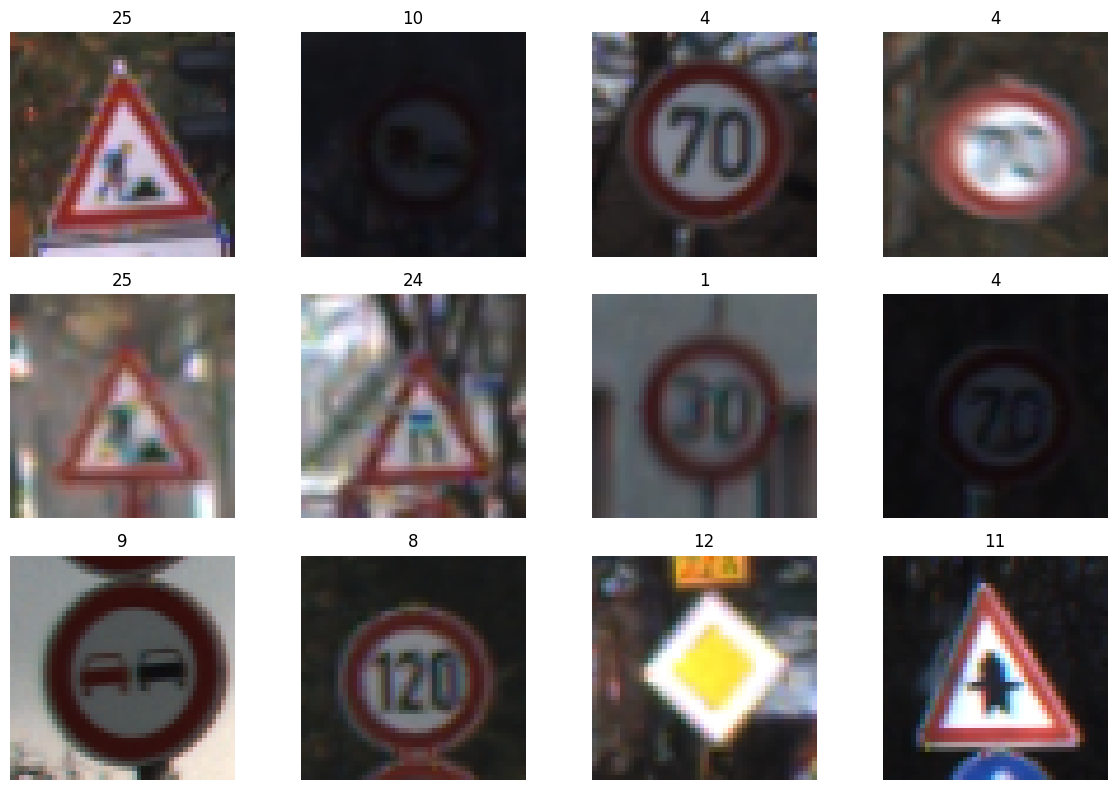

In [9]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(str(class_names[int(labels[i])]))
        plt.axis("off")
plt.tight_layout()
plt.show()

In [10]:
model = keras.Sequential([
    layers.Input(shape=(48, 48, 3)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(num_classes, activation="softmax")
])
model.compile(optimizer=keras.optimizers.Adam(0.001),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()
print("Output classes:", model.output_shape[-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 48, 48, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 48, 48, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 43)                  │           5,547 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 116,203 (453.92 KB)

 Trainable params: 115,755 (452.17 KB)

 Non-trainable params: 448 (1.75 KB)

Output classes: 43


In [11]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(
        filepath=str(PROJECT_DIR / "best_traffic_sign_model.keras"),
        monitor="val_accuracy", save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 149s 143ms/step - accuracy: 0.4111 - loss: 2.0519 - val_accuracy: 0.6239 - val_loss: 1.2598 - learning_rate: 0.0010
Epoch 2/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 131s 133ms/step - accuracy: 0.8272 - loss: 0.5707 - val_accuracy: 0.9369 - val_loss: 0.2101 - learning_rate: 0.0010
Epoch 3/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 131s 134ms/step - accuracy: 0.9149 - loss: 0.2813 - val_accuracy: 0.9282 - val_loss: 0.2984 - learning_rate: 0.0010
Epoch 4/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 133s 136ms/step - accuracy: 0.9458 - loss: 0.1828 - val_accuracy: 0.9834 - val_loss: 0.0753 - learning_rate: 0.0010
Epoch 5/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 133s 135ms/step - accuracy: 0.9547 - loss: 0.1478 - val_accuracy: 0.9630 - val_loss: 0.1418 - learning_rate: 0.0010
Epoch 6/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 134s 137ms/step - accuracy: 0.9630 - loss: 0.1224 - val_accuracy: 0.9953 - val_loss: 0.0235 - learning_rate: 0.0010
Epoch 7/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 136s 139ms/step - accura

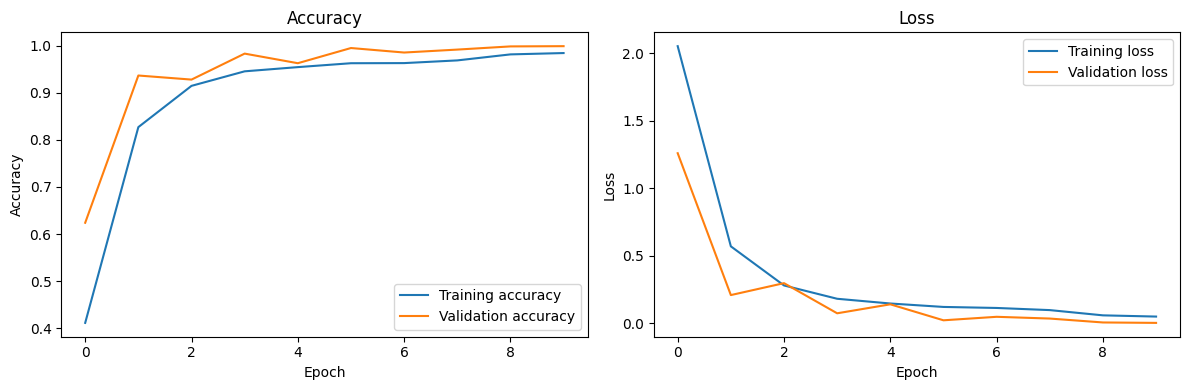

In [12]:
hist = pd.DataFrame(history.history)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist["accuracy"], label="Training accuracy")
plt.plot(hist["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist["loss"], label="Training loss")
plt.plot(hist["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss"); plt.legend()
plt.tight_layout(); plt.show()

In [13]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)
print("\nFINAL VALIDATION RESULTS")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")

y_true = np.concatenate([y.numpy() for _, y in val_ds])
y_prob = model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=list(range(num_classes)),
                            target_names=[str(c) for c in class_names], zero_division=0))

246/246 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.9992 - loss: 0.0044

FINAL VALIDATION RESULTS
Validation loss: 0.0044
Validation accuracy: 0.9992
Validation accuracy: 99.92%
246/246 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step

Classification report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.00      0.00      0.00         0
          10       0.00      0.00      0.00         0
          11       0.00      0.00      0.00         0
          12       0.00      0.00      0.00         0
          13       0.00      0.00      0.00         0
          14       0.00      0.00      0.00         0
          15       0.00      0.00      0.00         0
          16       0.00      0.00      0.00         0
          17       0.00      0.00      0.00         0
          18       0.00      0.00      0.00         0
          19       0.00      0.00      0.00         0
           2       0.00      0.00      0.00      

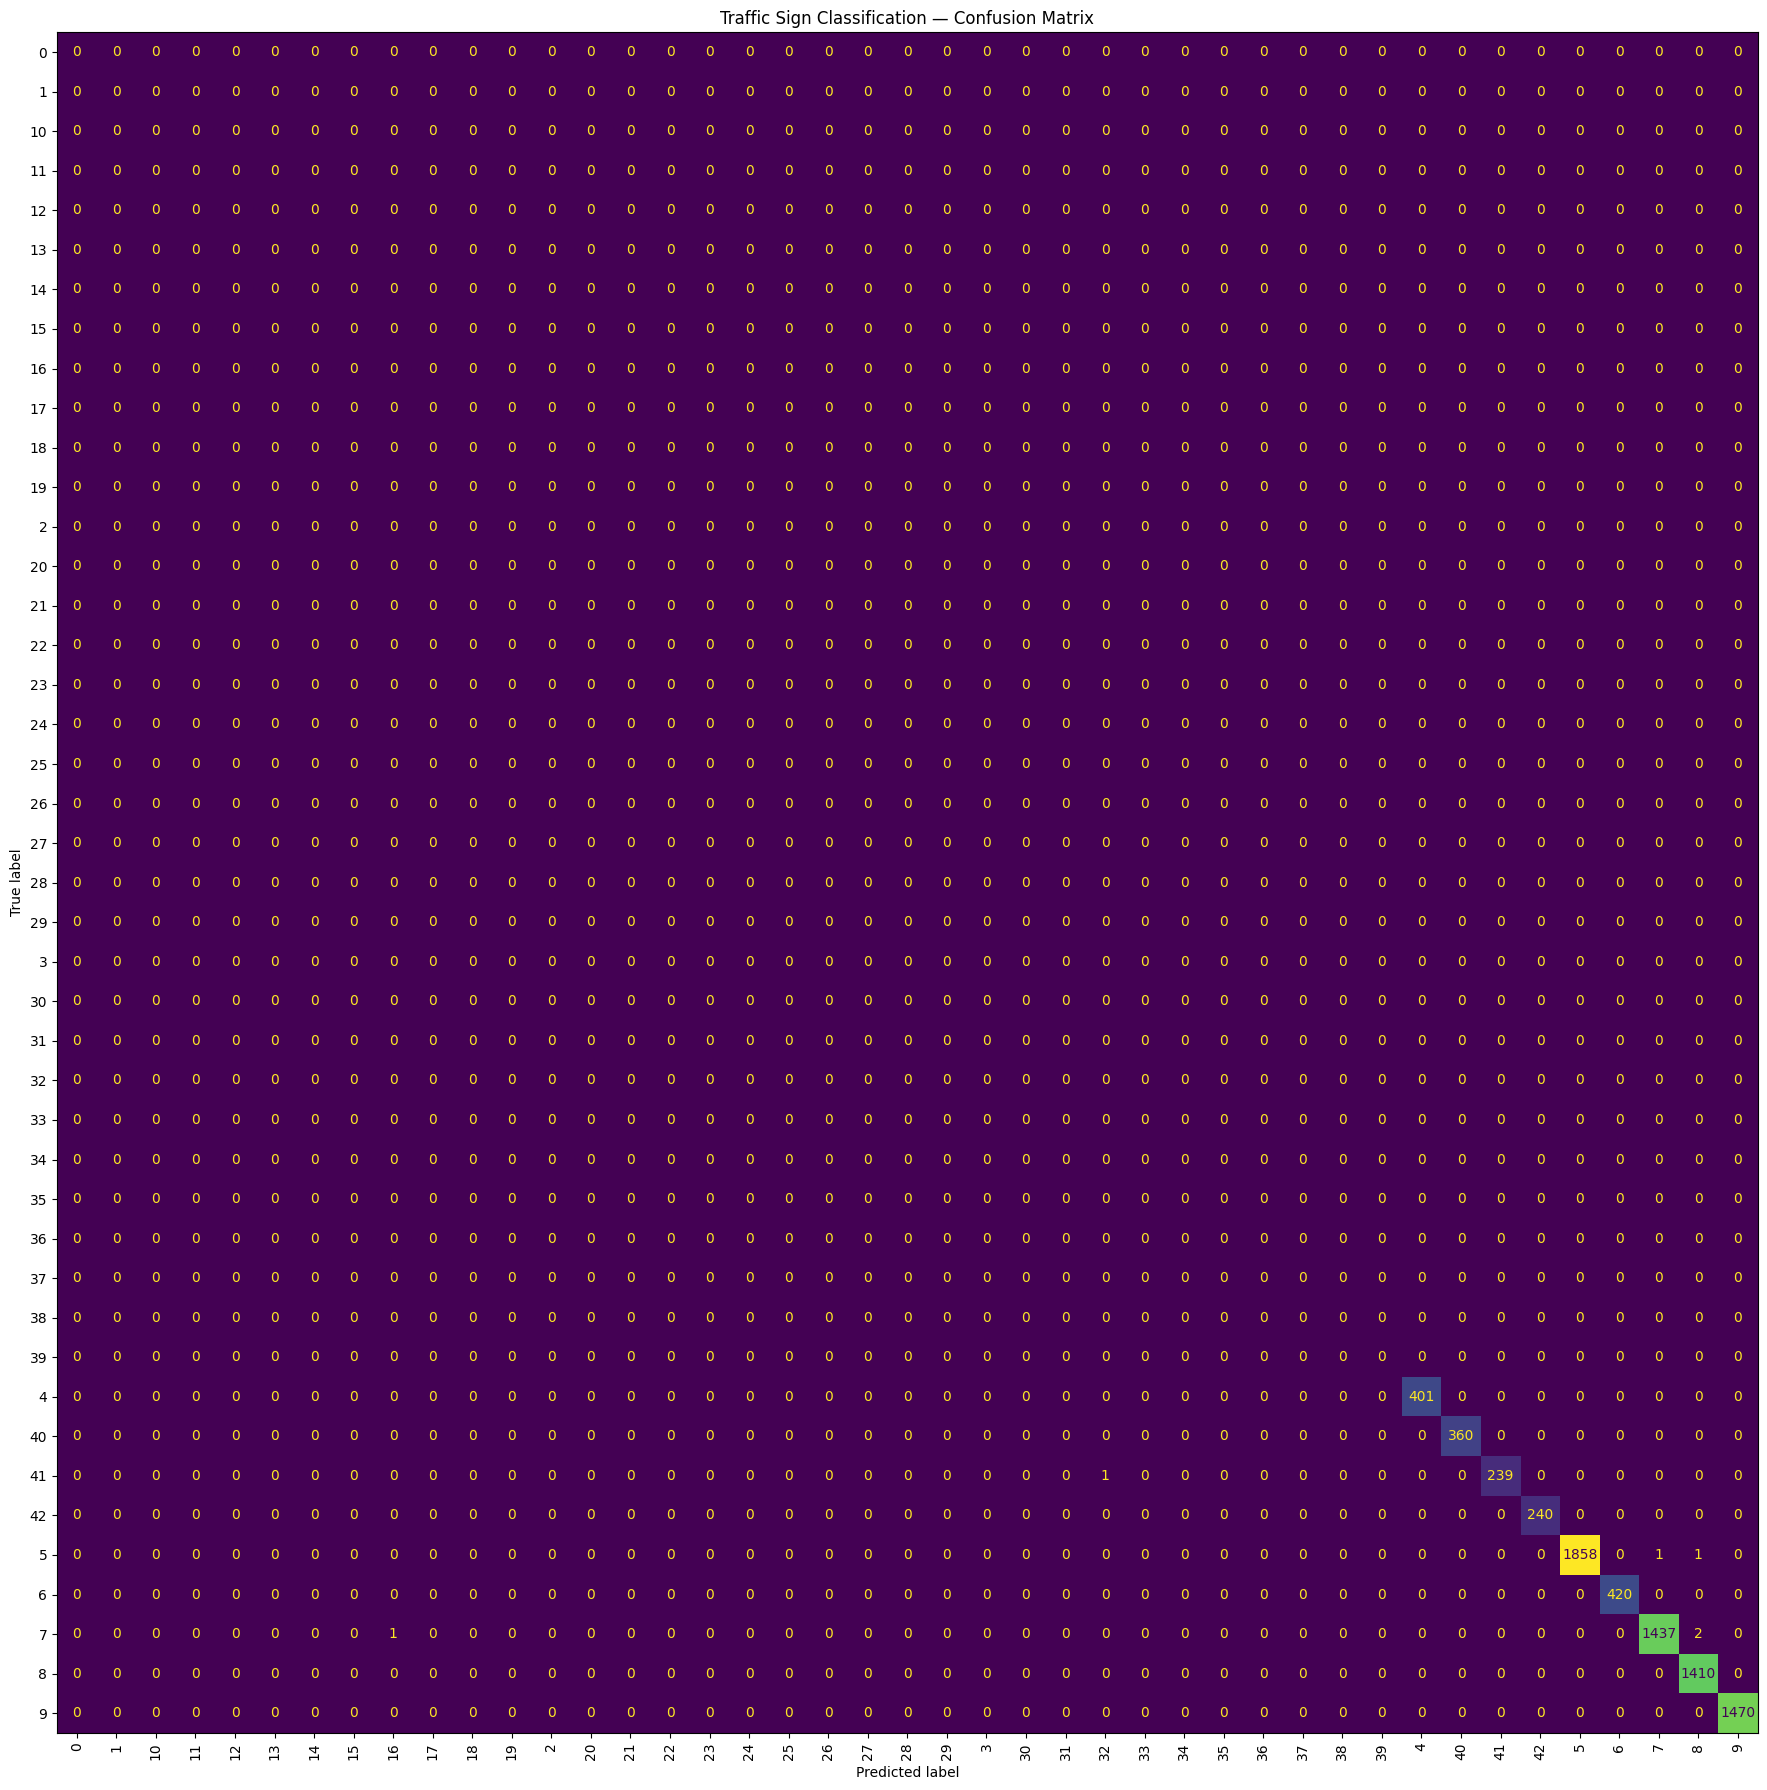

In [14]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
fig_size = max(8, min(18, num_classes * 0.45))
fig, ax = plt.subplots(figsize=(fig_size, fig_size))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation="vertical", colorbar=False, values_format="d"
)
plt.title("Traffic Sign Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
from IPython.display import display

def predict_traffic_sign(image_path):
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")
    img = keras.utils.load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
    arr = keras.utils.img_to_array(img)
    probs = model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
    best = int(np.argmax(probs))
    display(img)
    print("Predicted class:", class_names[best])
    print(f"Model confidence: {probs[best] * 100:.2f}%")
    print("\nTop predictions:")
    for idx in np.argsort(probs)[-min(5, num_classes):][::-1]:
        print(f"{class_names[int(idx)]}: {probs[idx] * 100:.2f}%")

# Example (replace with the actual path of a traffic-sign image):
# predict_traffic_sign(r"D:\2 nd project\sample_sign.png")

In [16]:
model_path = PROJECT_DIR / "traffic_sign_classifier.keras"
labels_path = PROJECT_DIR / "traffic_sign_class_names.json"
model.save(model_path)
with open(labels_path, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)
print("Model saved:", model_path)
print("Class names saved:", labels_path)

Model saved: D:\2 nd project\traffic_sign_classifier.keras
Class names saved: D:\2 nd project\traffic_sign_class_names.json
